# CNN ImageNet-1K Benchmark

So sánh pretrained nguyên bản: VGG16, GoogLeNet, ResNet50, DenseNet121, EfficientNet-B0 và MobileNetV2.
Notebook chỉ đọc output; không tải weights, train hoặc chạy benchmark.

Dữ liệu: ImageNet-1K validation, 500 ảnh (10 lớp ×50 ảnh), seed42.

Cả sáu weights được pretrained trên ImageNet-1K; recipe/optimizer/augmentation khác nhau.
Không phải sáu model do dự án này train cùng một pipeline. Khi đánh giá, cả sáu dùng đúng cùng500 ảnh.
Đúng/Sai trong bảng chính tính theo Top-1; Top-5 đúng là chỉ số riêng.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()
project = root if (root / 'src' / '1_benchmark.py').exists() else root / 'test_model_present'
runs = sorted((project / 'outputs').glob('lan_*'), key=lambda p: int(p.name.split('_')[1]))
RUN = runs[-1] if runs else None
results = pd.read_csv(RUN / 'results.csv') if RUN and (RUN / 'results.csv').exists() else pd.DataFrame()
if results.empty:
    print('Chưa có kết quả benchmark thật. Chuẩn bị ImageNet/manifest rồi chạy script riêng.')
else:
    print('Run:', RUN)
    summary = results[['model','n','top1_correct','top1_wrong','top1_percent',
                       'latency_ms','images_per_second','peak_allocated_mib']].rename(columns={
        'model':'Model','n':'Tổng ảnh','top1_correct':'Đúng','top1_wrong':'Sai',
        'top1_percent':'Accuracy (%)','latency_ms':'ms/ảnh (B1)',
        'images_per_second':'ảnh/s (B16)','peak_allocated_mib':'VRAM MiB (B16)'})
    display(summary.round(2))
    print('Chỉ số bổ sung:')
    display(results[['model','top5_correct','top5_percent','p95_ms','parameters_m']].round(2))


Run: D:\newtask\DL\test_model_present\outputs\lan_1


,Model,Tổng ảnh,Đúng,Sai,Accuracy (%),ms/ảnh (B1),ảnh/s (B16),VRAM MiB (B16)
0,densenet121,500,362,138,72.4,14.94,283.60,202.31
1,googlenet,500,356,144,71.2,6.83,738.30,152.90
2,resnet50,500,368,132,73.6,6.35,265.86,278.35
3,efficientnet_b0,500,381,119,76.2,8.53,651.78,198.97
4,vgg16,500,347,153,69.4,10.73,135.82,939.75
5,mobilenet_v2,500,358,142,71.6,5.96,842.26,192.14


Chỉ số bổ sung:


,model,top5_correct,top5_percent,p95_ms,parameters_m
0,densenet121,455,91.0,17.72,7.98
1,googlenet,455,91.0,9.32,6.62
2,resnet50,466,93.2,8.11,25.56
3,efficientnet_b0,476,95.2,11.28,5.29
4,vgg16,457,91.4,10.90,138.36
5,mobilenet_v2,456,91.2,9.67,3.50


## Accuracy và chi phí inference

Timing batch1 là forward trên tensor resident. Throughput và VRAM dùng batch riêng ghi trong bảng.


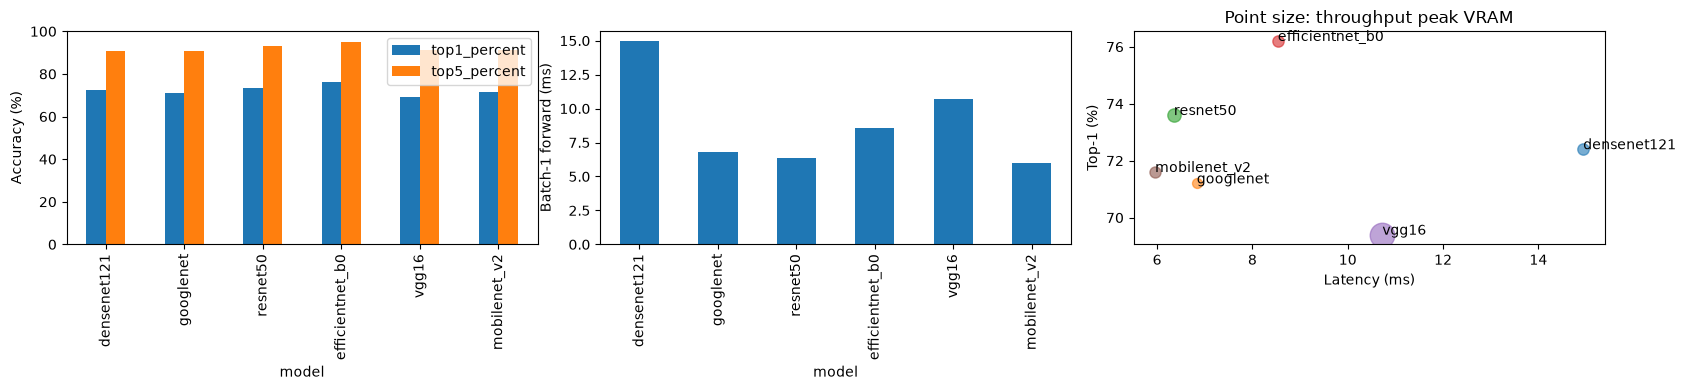

In [2]:
if not results.empty:
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    results.plot.bar(x='model', y=['top1_percent', 'top5_percent'], ax=axes[0])
    axes[0].set(ylabel='Accuracy (%)', ylim=(0, 100))
    results.plot.bar(x='model', y='latency_ms', ax=axes[1], legend=False)
    axes[1].set(ylabel='Batch-1 forward (ms)')
    for _, row in results.iterrows():
        vram = row['peak_allocated_mib']
        size = 60 if pd.isna(vram) else max(30, vram / 3)
        axes[2].scatter(row['latency_ms'], row['top1_percent'], s=size, alpha=.6)
        axes[2].annotate(row['model'], (row['latency_ms'], row['top1_percent']))
    axes[2].set(xlabel='Latency (ms)', ylabel='Top-1 (%)', title='Point size: throughput peak VRAM')
    plt.tight_layout(); plt.show()


## Đối chiếu cùng ảnh

Chọn ID từ snapshot của run. Bảng Top-5 dùng nhãn1.000 lớp; ảnh local cần giữ nguyên.


In [3]:
if not results.empty:
    manifest = json.loads((RUN / 'manifest.json').read_text())
    IMAGE_ID = manifest[0]['id']
    comparisons = []
    for name in results['model']:
        report = json.loads((RUN / f'{name}.json').read_text())
        predictions = json.loads((RUN / f'{name}_predictions.json').read_text())
        item = next(x for x in predictions if x['id'] == IMAGE_ID)
        names = report['categories']
        comparisons.append({'model':name, 'id':IMAGE_ID, 'true':names[item['true']],
            'top1':names[item['top5'][0]], 'correct':item['true']==item['top5'][0],
            'top5':[names[i] for i in item['top5']], 'scores':item['scores']})
    display(pd.DataFrame(comparisons))


,model,id,true,top1,correct,top5,scores
0,densenet121,imagenet1k/validation/16763,tabby,tabby,True,"[tabby, Egyptian cat, tiger cat, remote contro...","[0.3402574956417084, 0.2771819233894348, 0.203..."
1,googlenet,imagenet1k/validation/16763,tabby,tiger cat,False,"[tiger cat, tabby, Egyptian cat, mouse, remote...","[0.3932778239250183, 0.38948893547058105, 0.13..."
2,resnet50,imagenet1k/validation/16763,tabby,tiger cat,False,"[tiger cat, tabby, Egyptian cat, mouse, remote...","[0.6340020298957825, 0.22609896957874298, 0.05..."
3,efficientnet_b0,imagenet1k/validation/16763,tabby,tiger cat,False,"[tiger cat, tabby, mouse, running shoe, soccer...","[0.3444615304470062, 0.2154865711927414, 0.078..."
4,vgg16,imagenet1k/validation/16763,tabby,tiger cat,False,"[tiger cat, tabby, Egyptian cat, Cardigan, dum...","[0.1705905944108963, 0.1605062484741211, 0.069..."
5,mobilenet_v2,imagenet1k/validation/16763,tabby,tabby,True,"[tabby, tiger cat, Egyptian cat, remote contro...","[0.4894653558731079, 0.4031980335712433, 0.030..."


## Recall từng lớp và nhầm ra lớp ngoài

Giữ nguyên dự đoán1.000 lớp. Confusion dưới đây gộp990 lớp ngoài thành một cột để dễ xem, không đổi accuracy.


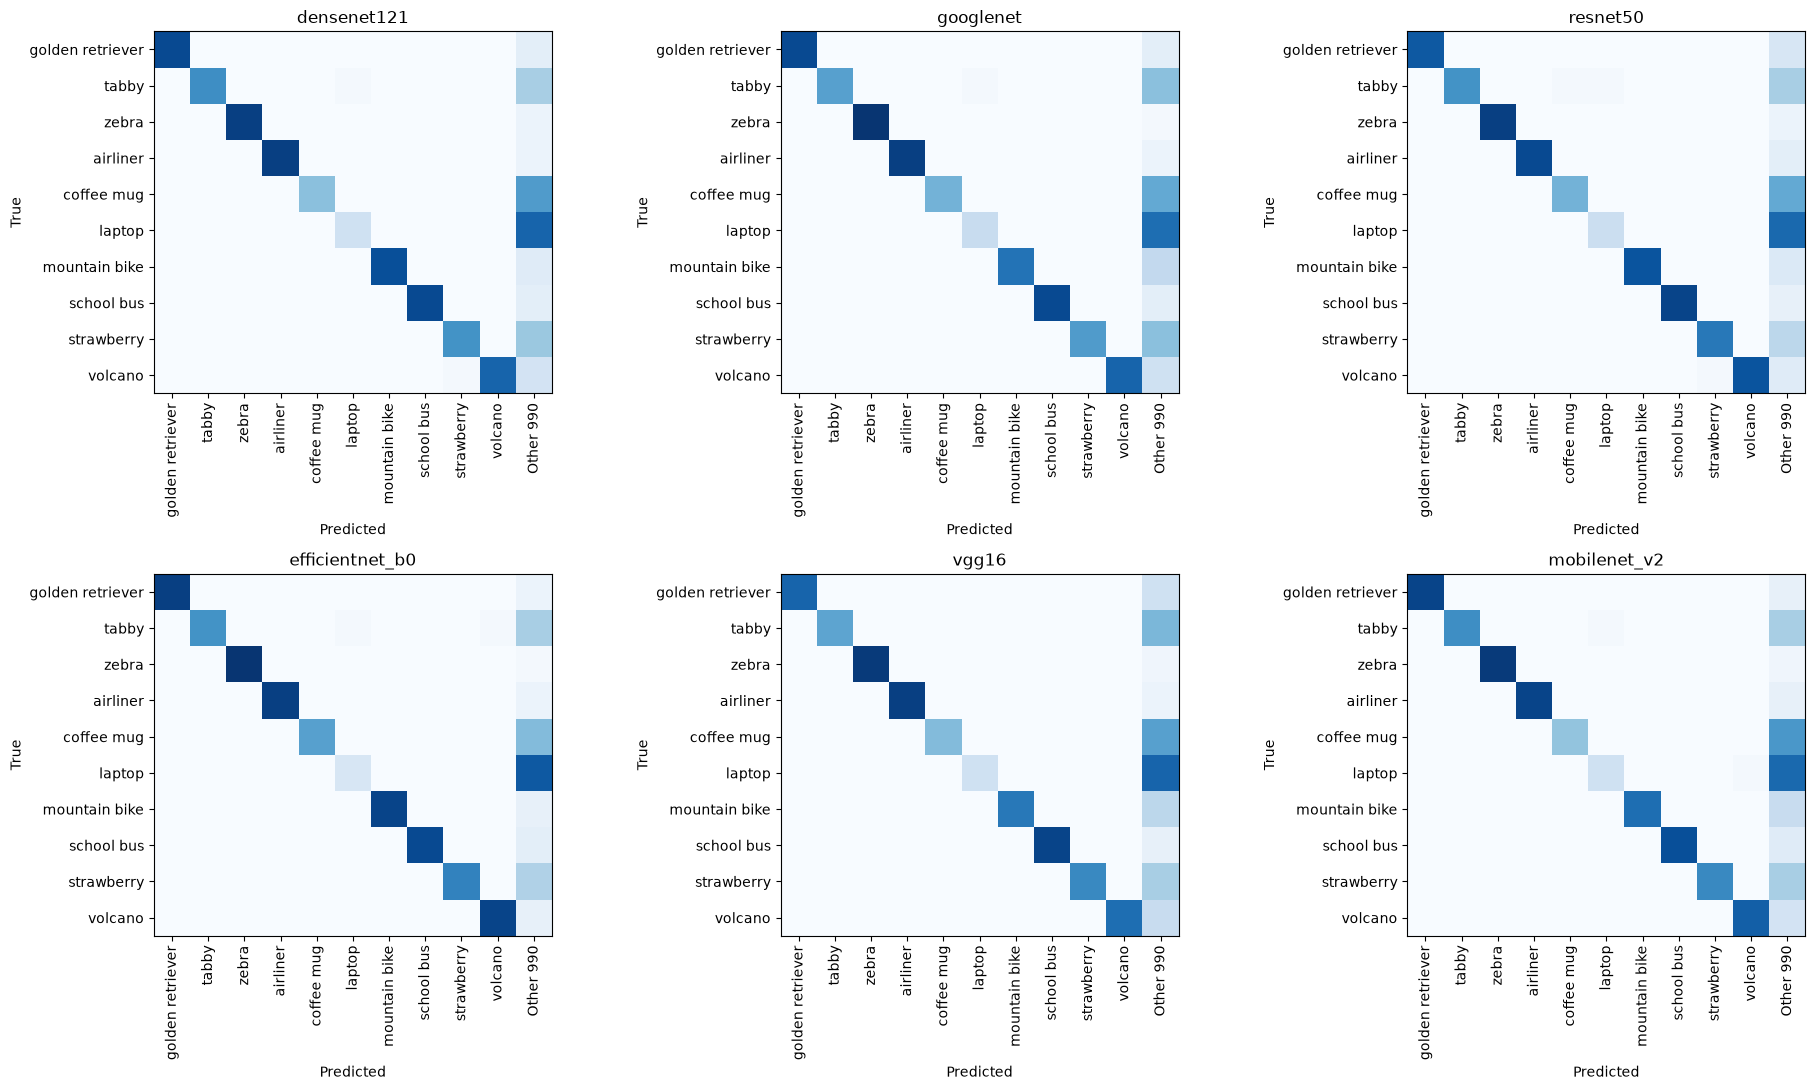

,model,class,support,correct,wrong,recall,outside_selected
0,densenet121,golden retriever,50,45,5,0.90,5
1,densenet121,tabby,50,32,18,0.64,17
2,densenet121,zebra,50,47,3,0.94,3
3,densenet121,airliner,50,47,3,0.94,3
4,densenet121,coffee mug,50,21,29,0.42,29
5,densenet121,laptop,50,10,40,0.20,40
6,densenet121,mountain bike,50,44,6,0.88,6
7,densenet121,school bus,50,45,5,0.90,5
8,densenet121,strawberry,50,31,19,0.62,19
9,densenet121,volcano,50,40,10,0.80,9


In [4]:
if not results.empty:
    import numpy as np
    selected = sorted({int(row['label']) for row in manifest})
    recall_rows = []
    fig, axes = plt.subplots(2, 3, figsize=(19, 11))
    for ax, name in zip(axes.flat, results['model']):
        report = json.loads((RUN / f'{name}.json').read_text())
        items = json.loads((RUN / f'{name}_predictions.json').read_text())
        names = report['categories']
        matrix = np.zeros((len(selected), len(selected) + 1), dtype=int)
        for item in items:
            actual, pred = item['true'], item['top5'][0]
            row = selected.index(actual)
            col = selected.index(pred) if pred in selected else len(selected)
            matrix[row, col] += 1
        for i, label in enumerate(selected):
            support = int(matrix[i].sum())
            recall_rows.append({'model':name,'class':names[label],'support':support,
                'correct':int(matrix[i,i]),'wrong':support-int(matrix[i,i]),
                'recall':float(matrix[i,i]/support),'outside_selected':int(matrix[i,-1])})
        ax.imshow(matrix, cmap='Blues', vmin=0, vmax=50)
        ax.set_xticks(range(len(selected)+1), [names[i] for i in selected]+['Other 990'], rotation=90)
        ax.set_yticks(range(len(selected)), [names[i] for i in selected])
        ax.set(title=name,xlabel='Predicted',ylabel='True')
    plt.tight_layout(); plt.show()
    display(pd.DataFrame(recall_rows))


## Giới hạn

Ghi đúng split và phạm vi mẫu. ImageNet-1K validation subset không phải official test; validation có thể đã được dùng trong phát triển model.
Một ảnh mỗi lớp có phương sai lớn; recipe pretrained khác nhau, không quy toàn bộ chênh lệch cho kiến trúc.
